# Assignment 2 – Part 3: Segmenting a Busy Karachi Road

**Student ID:** 26K-7618

**Goal:** segment every object on busy Karachi roads (road, buildings, people, cars, buses, motorcycles...) the same way the **Cityscapes** dataset labels its 50 European cities, and see how well a model trained on European streets handles Karachi.

**Photos:** 59 Karachi road photos..

### The plan
1. Load the photos and remove hidden location data
2. Run a **panoptic segmentation** model trained on Cityscapes (Mask2Former)
3. **Protect privacy:** blur faces and number plates before showing or saving anything
4. Show the segmentation: by class, and by individual object
5. Count what is on the road
6. Look at where the model gets confused on Karachi roads (**domain gap**)
7. Save the anonymised results

## Privacy and ethics

These photos show real people and vehicles in public places, so these rules apply:

**Using someone else's photos**
- The source is credited above, and the photos stay the author's property.
- The original photos are **not** committed to my git repository or shared further (the `karachi_photos` folder is in `.gitignore`). Only anonymised results are saved.

**Good practice when photographing roads** (these apply to the source photos, and to any further photos added to this work)
- Shoot from a distance (for example from a footbridge or the roadside) to capture the *scene*, not individuals, and without zooming in on anyone.
- Do not photograph anyone who objects, and avoid close shots of women and children.
- Avoid sensitive locations (police or army checkpoints, hospitals, places of worship during prayers).
- Stay safe and out of traffic.

**While processing the photos**
- **Hidden data:** phone photos store GPS location and phone details (EXIF). The notebook removes all of it.
- **Faces and number plates** are blurred automatically, and then **I check every photo by eye** and add manual blur boxes for anything missed.
- The model runs **locally on my laptop**, so the original photos are never uploaded anywhere.
- Only the **anonymised** versions are displayed in this notebook or saved.

This follows Cityscapes itself, which blurs all faces and licence plates in its public images.

## 1. Setup

The photos (`.jpg` / `.jpeg` / `.png` / `.webp`) are read from the `karachi_photos` folder next to this notebook. All settings are kept in one cell below.

In [1]:
import os

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2
import torch
from PIL import Image, ImageOps
from huggingface_hub import hf_hub_download
from transformers import AutoImageProcessor, Mask2FormerForUniversalSegmentation
from transformers.utils import logging

logging.set_verbosity_error()   # hide long, harmless model-loading messages

In [2]:
PHOTO_FOLDER = "karachi_photos"
OUTPUT_FOLDER = "karachi_outputs"
MAX_SIDE = 1280             # photos are shrunk so the longest side is 1280 px (faster, enough detail)

MODEL_NAME = "facebook/mask2former-swin-small-cityscapes-panoptic"
SCORE_THRESHOLD = 0.5       # ignore objects the model is less than 50% sure about

# privacy settings
FACE_CONFIDENCE = 0.6       # face detector confidence needed to count as a face
HEAD_FRACTION = 0.25        # blur the top 25% of every person / rider (their head)
PLATE_FRACTION = 0.65       # blur the bottom 65% of every vehicle (number plates, people inside)

SHOW_COUNT = 6              # how many photos get the large, detailed view (all photos are still processed)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("Using device:", device)

Using device: mps


### Cityscapes classes and colours

The model predicts the **19 Cityscapes classes**. We use the official Cityscapes colours so the results look like the examples on the Cityscapes website.

Cityscapes splits the classes into two groups (the same idea as the Panoptic Segmentation paper from Part 1):
- **stuff:** areas with no clear count, like road, sky and buildings
- **things:** objects we can count one by one, like person, car and bus

In [3]:
CLASS_NAMES = [
    "road", "sidewalk", "building", "wall", "fence", "pole", "traffic light", "traffic sign",
    "vegetation", "terrain", "sky", "person", "rider", "car", "truck", "bus", "train",
    "motorcycle", "bicycle",
]

CLASS_COLORS = np.array([
    (128, 64, 128), (244, 35, 232), (70, 70, 70), (102, 102, 156), (190, 153, 153),
    (153, 153, 153), (250, 170, 30), (220, 220, 0), (107, 142, 35), (152, 251, 152),
    (70, 130, 180), (220, 20, 60), (255, 0, 0), (0, 0, 142), (0, 0, 70),
    (0, 60, 100), (0, 80, 100), (0, 0, 230), (119, 11, 32),
], dtype=np.uint8)

THING_CLASSES = ["person", "rider", "car", "truck", "bus", "train", "motorcycle", "bicycle"]
STUFF_CLASSES = [name for name in CLASS_NAMES if name not in THING_CLASSES]

PEOPLE_CLASSES = ["person", "rider"]
VEHICLE_CLASSES = ["car", "truck", "bus", "motorcycle"]

## 2. Load the photos

For each photo:
- `exif_transpose` rotates it the right way up (phones store rotation separately)
- it's shrunk to at most 1280 px
- it's rebuilt from raw pixels, which **drops all hidden metadata** (GPS location, phone model, time)

The file names are long (like `WhatsApp Image 2026-11-05 at 12.18.19 AM.jpeg`), so each photo gets a short name: `road_01`, `road_02`, ... The output shows which file each short name belongs to, and whether it had a GPS location stored in it.

In [4]:
def load_photo(path):
    image = Image.open(path)
    had_gps = bool(image.getexif().get_ifd(0x8825))   # 0x8825 is the GPS section of EXIF

    image = ImageOps.exif_transpose(image).convert("RGB")
    image.thumbnail((MAX_SIDE, MAX_SIDE))
    image = Image.fromarray(np.array(image))           # fresh copy: pixels only, no metadata
    return image, had_gps


os.makedirs(PHOTO_FOLDER, exist_ok=True)
file_names = sorted(
    name for name in os.listdir(PHOTO_FOLDER)
    if name.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
)
assert file_names, f"No photos found in the '{PHOTO_FOLDER}' folder."

photos = {}
for number, file_name in enumerate(file_names, start=1):
    name = f"road_{number:02d}"
    image, had_gps = load_photo(os.path.join(PHOTO_FOLDER, file_name))
    photos[name] = image
    gps_note = "had GPS -> removed" if had_gps else "no GPS"
    print(f"{name}: {image.width:4d}x{image.height:<4d} {gps_note:18s} <- {file_name}")

print(f"\nLoaded {len(photos)} photos")

road_01:  800x480  no GPS             <- 1203221515c6e0d.webp
road_02:  800x800  no GPS             <- 1762782317502.jpg
road_03:  800x480  no GPS             <- 6394f92df31b7.jpg
road_04:  691x480  no GPS             <- 66ef4913f2b9e.jpg
road_05:  963x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.18.19 AM.jpeg
road_06:  963x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.18.20 AM (1).jpeg
road_07:  963x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.18.20 AM.jpeg
road_08:  963x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.18.21 AM (1).jpeg
road_09:  963x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.18.21 AM (2).jpeg
road_10:  963x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.18.21 AM (3).jpeg
road_11:  963x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.18.21 AM.jpeg
road_12:  963x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.18.22 AM (1).jpeg
road_13:  963x1280 no GPS             <- What

road_14:  963x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.18.22 AM.jpeg


road_15:  963x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.18.23 AM (1).jpeg
road_16:  963x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.18.23 AM (2).jpeg
road_17:  963x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.18.23 AM (3).jpeg
road_18:  963x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.18.23 AM.jpeg
road_19:  963x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.18.24 AM (1).jpeg
road_20:  963x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.18.24 AM (2).jpeg
road_21:  963x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.18.24 AM (3).jpeg
road_22:  963x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.18.24 AM.jpeg
road_23:  963x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.18.25 AM.jpeg
road_24:  720x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.19.01 AM.jpeg
road_25:  720x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.19.02 AM (1).jpeg


road_26: 1280x562  no GPS             <- WhatsApp Image 2026-11-05 at 12.19.02 AM.jpeg
road_27:  590x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.19.21 AM (1).jpeg


road_28:  590x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.19.21 AM.jpeg
road_29:  960x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.19.43 AM (1).jpeg
road_30:  960x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.19.43 AM.jpeg
road_31: 1280x960  no GPS             <- WhatsApp Image 2026-11-05 at 12.20.21 AM.jpeg
road_32:  800x480  no GPS             <- WhatsApp Image 2026-11-05 at 12.20.22 AM (1).jpeg
road_33:  960x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.20.22 AM.jpeg
road_34:  899x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.20.23 AM (1).jpeg
road_35:  720x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.20.23 AM (2).jpeg
road_36:  720x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.20.23 AM (3).jpeg
road_37:  992x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.20.23 AM.jpeg
road_38:  766x1280 no GPS             <- WhatsApp Image 2026-11-05 at 12.20.24 AM (1).jpeg
road_39: 1280x720  

road_56:  853x1280 no GPS             <- pexels-aniquah-riaz-2165265882-40618005.jpg
road_57:  960x1280 no GPS             <- pexels-hamza-awan-1282073526-40084585.jpg
road_58:  960x1280 no GPS             <- pexels-zaktech90-13949162.jpg

Loaded 58 photos


## 3. The models

### Mask2Former (segmentation)
**Mask2Former** (Cheng et al., CVPR 2022) is a transformer-based model that handles semantic, instance and panoptic segmentation with one design. Instead of labelling pixels one by one, it predicts a set of **masks**, each with a class. This version was trained on Cityscapes, so it knows the 19 classes above.

We use it for **panoptic segmentation**: every pixel gets a class, *and* every thing (each person, each car) gets its own ID.

### YuNet (face detection)
A small, fast face detector from OpenCV. We use it only for privacy, to find faces to blur.

The first run downloads the models (~280 MB). After that they're cached.

In [5]:
processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
model = Mask2FormerForUniversalSegmentation.from_pretrained(MODEL_NAME).to(device).eval()

yunet_path = hf_hub_download("opencv/face_detection_yunet", "face_detection_yunet_2023mar.onnx")
face_detector = cv2.FaceDetectorYN.create(yunet_path, "", (320, 320), FACE_CONFIDENCE)

print("Models loaded")

Loading weights:   0%|          | 0/758 [00:00<?, ?it/s]

Models loaded


[ WARN:0@9.824] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


## 4. Run panoptic segmentation

`segment_photo` gives back three things:
- `class_map`: same size as the photo, each pixel holds a class number (`-1` means the model wasn't sure)
- `segment_map`: same size as the photo, each pixel holds the **id** of the segment it belongs to
- `segments`: a list with one entry per region found, with its id, class, confidence score and bounding box

To get the mask of one segment we just compare: `segment_map == seg["id"]`. We don't store a separate mask for every segment, because with 59 photos and ~40 segments each, that would take several GB of memory. Storing the two maps in small number types (`int8`, `int16`) keeps everything light.

`label_ids_to_fuse` tells the model to merge all pieces of the same *stuff* class (for example, two separate patches of sky become one "sky" segment). Things are never merged, so each car stays separate.

> The model runs on the original photo *in memory*. Nothing is shown or saved until the privacy step below.

In [6]:
STUFF_IDS = {CLASS_NAMES.index(name) for name in STUFF_CLASSES}


def box_around(mask):
    ys, xs = np.where(mask)
    return xs.min(), ys.min(), xs.max(), ys.max()


def segment_photo(image):
    inputs = processor(images=image, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = model(**inputs)

    result = processor.post_process_panoptic_segmentation(
        outputs,
        threshold=SCORE_THRESHOLD,
        label_ids_to_fuse=STUFF_IDS,
        target_sizes=[(image.height, image.width)],
    )[0]

    segment_map = result["segmentation"].cpu().numpy().astype(np.int16)   # 0 = nothing found
    class_map = np.full(segment_map.shape, -1, dtype=np.int8)

    segments = []
    for info in result["segments_info"]:
        mask = segment_map == info["id"]
        class_map[mask] = info["label_id"]
        segments.append({
            "id": info["id"],
            "class": CLASS_NAMES[info["label_id"]],
            "score": info["score"],
            "box": box_around(mask),
        })
    return class_map, segment_map, segments


results = {}
for name, image in photos.items():
    class_map, segment_map, segments = segment_photo(image)
    results[name] = {"class_map": class_map, "segment_map": segment_map, "segments": segments}

total = sum(len(r["segments"]) for r in results.values())
print(f"Segmented {len(results)} photos, {total} segments found in total")

Segmented 58 photos, 905 segments found in total


## 5. Privacy: blur faces and number plates

Three automatic layers, plus a manual one:

| Layer | What it catches | How |
|---|---|---|
| 1. Face detector | faces close enough to see clearly | YuNet |
| 2. Heads of people | faces too small or turned away for the detector | top 25% of every *person* / *rider* the segmentation found |
| 3. Number plates | plates on cars, buses, rickshaws, bikes (and passengers behind windows) | bottom 65% of every vehicle the segmentation found |
| 4. Manual boxes | anything the first three missed | boxes added by hand after checking every photo (`EXTRA_BLUR_BOXES`) |

Blurring is done by **pixelating**: the area is shrunk to a few big blocks and stretched back, so the detail can't be recovered.

Using the segmentation masks for layers 2 and 3 is a nice side effect: the model we're studying also helps protect privacy.

In [7]:
# Add a box here for anything the automatic blurring missed.
# Format: "photo name": [(x1, y1, x2, y2), ...]  (pixel coordinates; use the axis numbers on the check images below)
EXTRA_BLUR_BOXES = {
    # found when checking the photos by eye:
    "road_48": [(448, 198, 502, 258),     # two pedestrians, too small for the detectors
                (495, 283, 558, 338)],    # rickshaw driver
    "road_57": [(415, 548, 610, 605),     # rickshaw driver (the rickshaw itself was not recognised as a vehicle)
                (515, 640, 620, 720)],    # rickshaw number plate
}


def find_privacy_boxes(image, segments, name):
    boxes = []

    # 1. faces from the face detector (box made 25% bigger to cover hair and edges)
    bgr = cv2.cvtColor(np.array(image), cv2.COLOR_RGB2BGR)
    face_detector.setInputSize((image.width, image.height))
    _, faces = face_detector.detect(bgr)
    if faces is not None:
        for face in faces:
            x, y, w, h = face[:4]
            pad_x, pad_y = w * 0.25, h * 0.25
            boxes.append((x - pad_x, y - pad_y, x + w + pad_x, y + h + pad_y))

    for seg in segments:
        x1, y1, x2, y2 = seg["box"]
        height = y2 - y1
        # 2. head area of people and riders
        if seg["class"] in PEOPLE_CLASSES:
            boxes.append((x1, y1, x2, y1 + height * HEAD_FRACTION))
        # 3. lower part of vehicles, where number plates are
        if seg["class"] in VEHICLE_CLASSES:
            boxes.append((x1, y2 - height * PLATE_FRACTION, x2, y2))

    # 4. manual boxes
    boxes += EXTRA_BLUR_BOXES.get(name, [])

    return [tuple(int(round(v)) for v in box) for box in boxes]


def pixelate(pixels, box, blocks=6):
    height, width = pixels.shape[:2]
    x1, y1, x2, y2 = box
    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(width, x2), min(height, y2)
    if x2 - x1 < 2 or y2 - y1 < 2:
        return

    region = pixels[y1:y2, x1:x2]
    h, w = region.shape[:2]
    small_w = blocks
    small_h = max(1, round(blocks * h / w))
    small = cv2.resize(region, (small_w, small_h), interpolation=cv2.INTER_AREA)
    pixels[y1:y2, x1:x2] = cv2.resize(small, (w, h), interpolation=cv2.INTER_NEAREST)


for name, image in photos.items():
    boxes = find_privacy_boxes(image, results[name]["segments"], name)
    pixels = np.array(image)
    for box in boxes:
        pixelate(pixels, box)

    results[name]["safe_image"] = Image.fromarray(pixels)
    results[name]["privacy_boxes"] = boxes

total = sum(len(r["privacy_boxes"]) for r in results.values())
print(f"Blurred {total} areas across {len(results)} photos")

Blurred 579 areas across 58 photos


### Check every photo by eye

The yellow boxes show what was blurred. Every photo was checked by eye, including close-ups of the riskiest ones (people near the camera, visible number plates). The check found **3 areas the automatic layers missed** in 2 photos, which were fixed with the manual boxes above:
- `road_57`: the rickshaw's number plate and the driver area. The model did not recognise the rickshaw as a vehicle, so layer 3 never covered it.
- `road_48`: two pedestrians and a rickshaw driver, too small for both detectors.

`check_photo(name)` shows a single photo at full size with pixel coordinates; it was used to place the manual boxes.

From here on, **only the blurred image (`safe_image`) is ever shown or saved.**

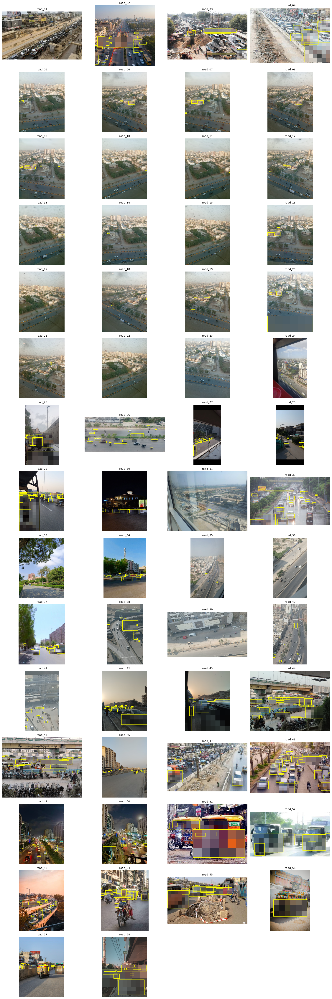

In [8]:
def draw_privacy_boxes(ax, name):
    ax.imshow(results[name]["safe_image"])
    for x1, y1, x2, y2 in results[name]["privacy_boxes"]:
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="yellow", linewidth=1))


def check_photo(name):
    fig, ax = plt.subplots(figsize=(12, 8))
    draw_privacy_boxes(ax, name)
    ax.set_title(f"{name}: blurred areas")
    plt.show()


columns = 4
rows = (len(photos) + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(18, 3.6 * rows))
for ax in axes.flat:
    ax.axis("off")
for ax, name in zip(axes.flat, photos):
    draw_privacy_boxes(ax, name)
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.show()

## 6. Look at the segmentation

For each photo we show three views:
1. **Photo** (blurred)
2. **Semantic view:** each pixel coloured by its class. All cars share one colour, all people share another, and so on. This is how the Cityscapes examples look.
3. **Instance view:** only the *things*, each with its own colour and label, which shows that car #1 and car #2 are separate objects. Together with the semantic view, this is **panoptic** segmentation.

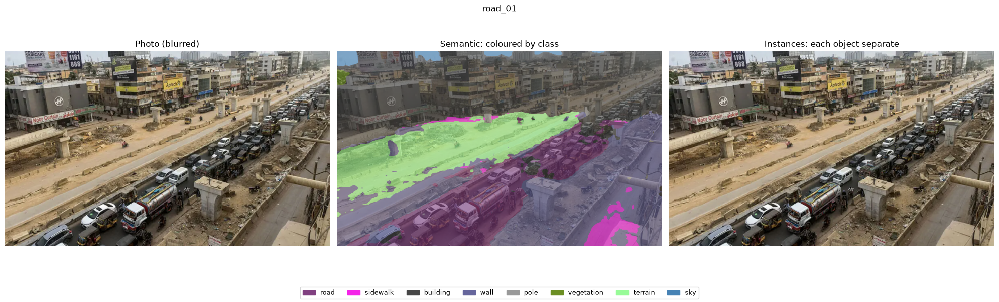

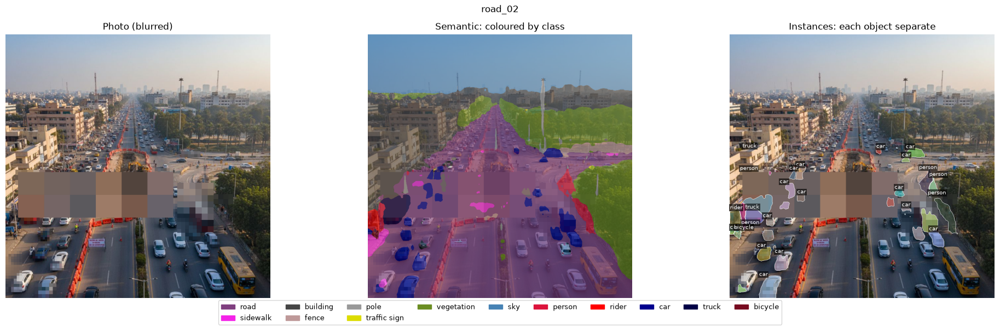

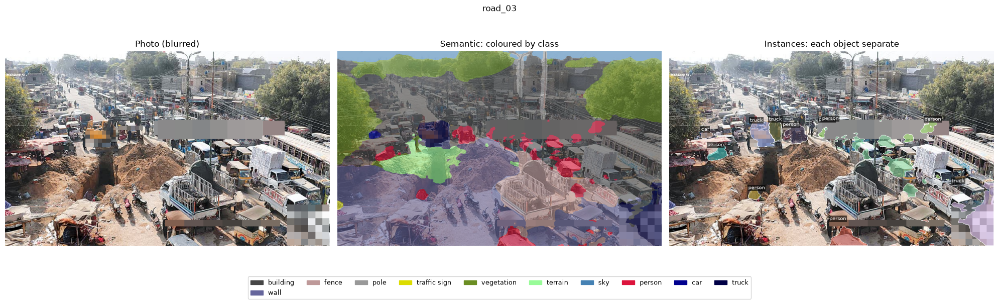

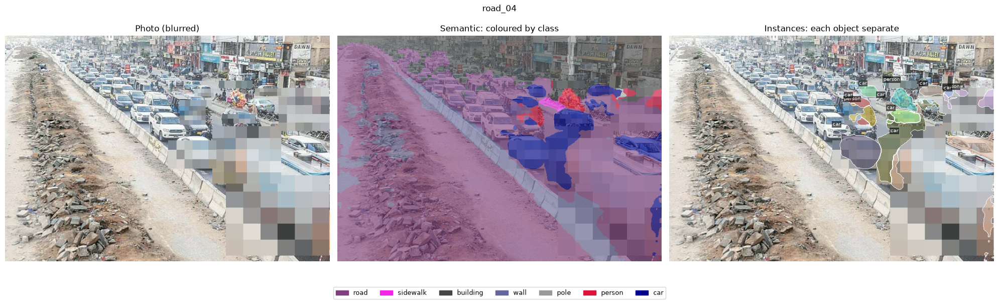

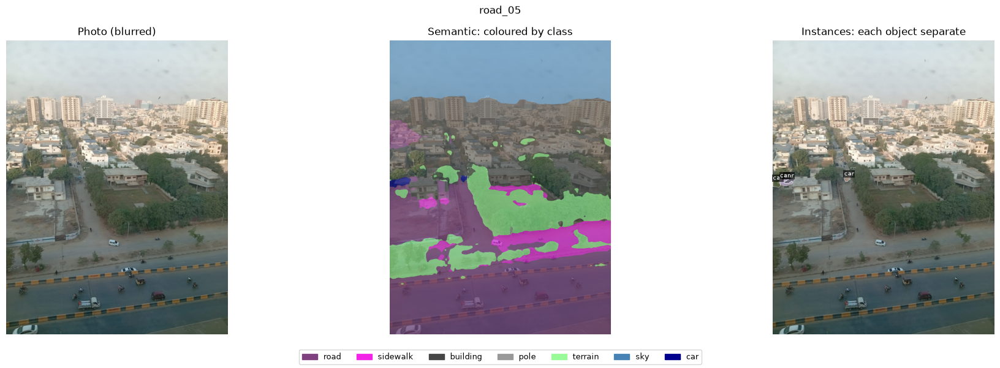

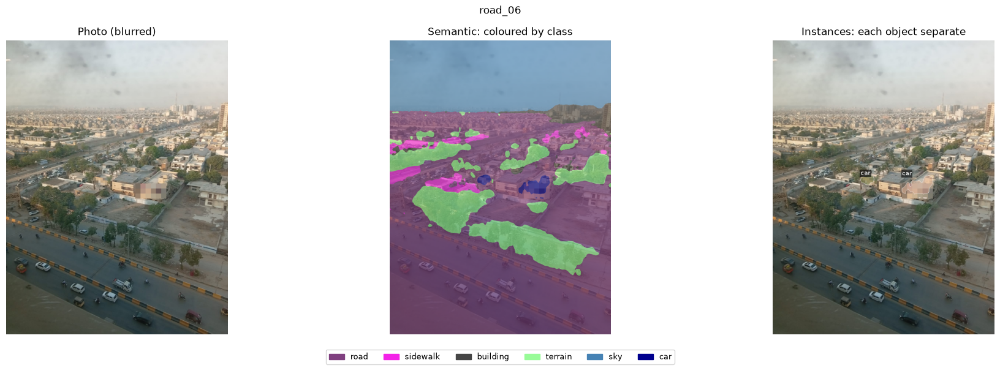

In [9]:
def color_by_class(class_map):
    colored = np.zeros((*class_map.shape, 3), dtype=np.uint8)
    known = class_map >= 0
    colored[known] = CLASS_COLORS[class_map[known]]
    return colored


def blend(image, colors, mask, strength=0.6):
    pixels = np.array(image).astype(float)
    pixels[mask] = (1 - strength) * pixels[mask] + strength * colors[mask]
    return pixels.astype(np.uint8)


def draw_instances(image, segment_map, segments):
    pixels = np.array(image).copy()
    rng = np.random.default_rng(0)
    for seg in segments:
        if seg["class"] not in THING_CLASSES:
            continue
        color = rng.integers(60, 255, size=3)
        mask = segment_map == seg["id"]
        pixels[mask] = (0.45 * pixels[mask] + 0.55 * color).astype(np.uint8)
        outline, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(pixels, outline, -1, (255, 255, 255), 1)
    return pixels


def class_legend(class_map):
    present = [i for i in np.unique(class_map) if i >= 0]
    return [patches.Patch(color=CLASS_COLORS[i] / 255, label=CLASS_NAMES[i]) for i in present]


def show_segmentation(name):
    safe = results[name]["safe_image"]
    class_map = results[name]["class_map"]
    segments = results[name]["segments"]

    semantic = blend(safe, color_by_class(class_map), class_map >= 0)
    instances = draw_instances(safe, results[name]["segment_map"], segments)

    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    axes[0].imshow(safe)
    axes[0].set_title("Photo (blurred)")
    axes[1].imshow(semantic)
    axes[1].set_title("Semantic: coloured by class")
    axes[2].imshow(instances)
    axes[2].set_title("Instances: each object separate")

    for seg in segments:
        if seg["class"] in THING_CLASSES:
            x1, y1, _, _ = seg["box"]
            axes[2].text(x1, y1, seg["class"], color="white", fontsize=7,
                         bbox=dict(facecolor="black", alpha=0.6, pad=1, linewidth=0))

    for ax in axes:
        ax.axis("off")
    fig.legend(handles=class_legend(class_map), loc="lower center", ncol=10, fontsize=9)
    fig.suptitle(name)
    plt.tight_layout(rect=(0, 0.06, 1, 1))
    plt.show()


for name in list(photos)[:SHOW_COUNT]:
    show_segmentation(name)

One more detailed example, `road_57`: a street-level shot of an auto-rickshaw. The model does not recognise the rickshaw at all (measured in section 8):

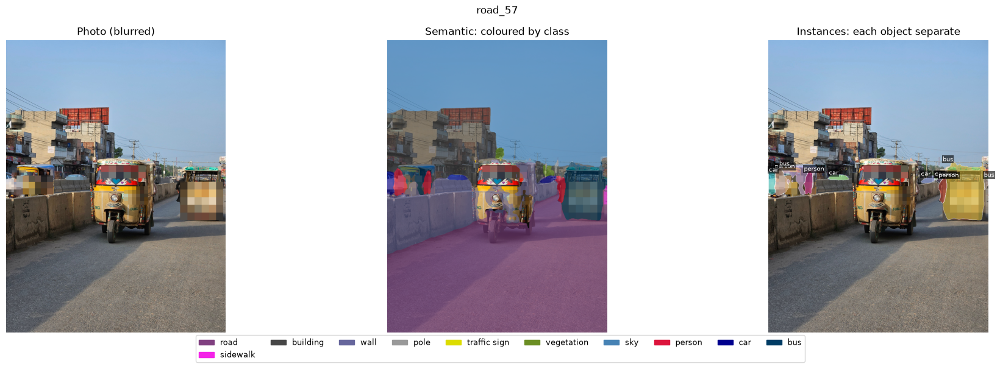

In [10]:
show_segmentation("road_57")

### All photos at a glance (semantic view)

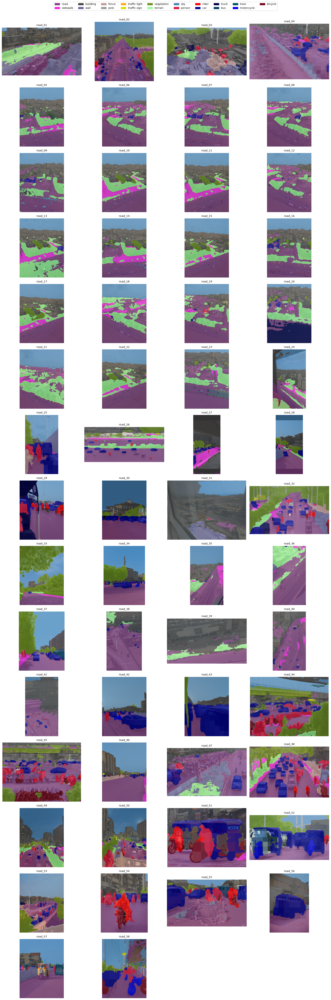

In [11]:
columns = 4
rows = (len(photos) + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(18, 3.6 * rows))
for ax in axes.flat:
    ax.axis("off")
for ax, name in zip(axes.flat, photos):
    class_map = results[name]["class_map"]
    ax.imshow(blend(results[name]["safe_image"], color_by_class(class_map), class_map >= 0, strength=0.7))
    ax.set_title(name, fontsize=10)

all_classes = [patches.Patch(color=CLASS_COLORS[i] / 255, label=CLASS_NAMES[i]) for i in range(len(CLASS_NAMES))]
fig.legend(handles=all_classes, loc="upper center", ncol=10, fontsize=10, bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(rect=(0, 0, 1, 0.985))
plt.show()

## 7. What is on the road?

**Things:** how many of each object the model counted in each photo.

**Stuff:** on average, what percentage of a photo is road, building, sky and so on.

In [12]:
print(f"{'Photo':10s}" + "".join(f"{c:>11s}" for c in THING_CLASSES))
print("-" * (10 + 11 * len(THING_CLASSES)))

total_counts = {c: 0 for c in THING_CLASSES}
for name in photos:
    counts = {c: 0 for c in THING_CLASSES}
    for seg in results[name]["segments"]:
        if seg["class"] in THING_CLASSES:
            counts[seg["class"]] += 1
            total_counts[seg["class"]] += 1
    print(f"{name:10s}" + "".join(f"{counts[c]:11d}" for c in THING_CLASSES))

print("-" * (10 + 11 * len(THING_CLASSES)))
print(f"{'TOTAL':10s}" + "".join(f"{total_counts[c]:11d}" for c in THING_CLASSES))

Photo          person      rider        car      truck        bus      train motorcycle    bicycle
--------------------------------------------------------------------------------------------------
road_01             0          0          0          0          0          0          0          0
road_02             5          1         15          2          0          0          0          1
road_03             7          0          1          3          0          0          0          0
road_04             3          0          8          0          0          0          0          0
road_05             0          0          4          0          0          0          0          0
road_06             0          0          2          0          0          0          0          0
road_07             0          0          5          0          0          0          0          0
road_08             0          0          1          0          0          0          0          0
road_09   

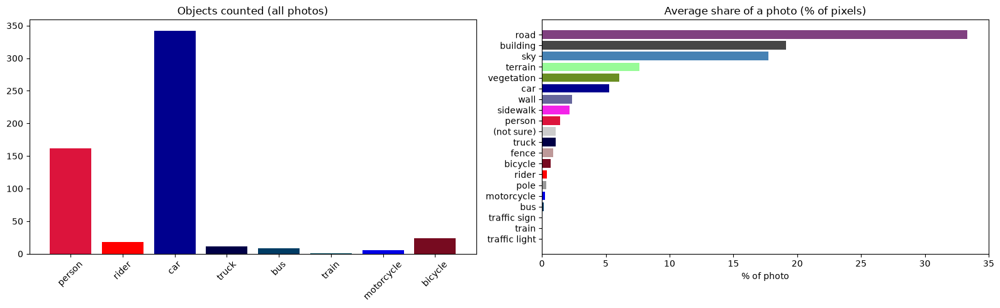

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# total number of each thing across all photos
thing_colors = [CLASS_COLORS[CLASS_NAMES.index(c)] / 255 for c in THING_CLASSES]
axes[0].bar(THING_CLASSES, [total_counts[c] for c in THING_CLASSES], color=thing_colors)
axes[0].set_title("Objects counted (all photos)")
axes[0].tick_params(axis="x", rotation=45)

# average share of every class (and "not sure") over all photos
labels = CLASS_NAMES + ["(not sure)"]
class_ids = list(range(len(CLASS_NAMES))) + [-1]
average_share = [np.mean([100 * (results[n]["class_map"] == i).mean() for n in photos]) for i in class_ids]
bar_colors = [CLASS_COLORS[i] / 255 for i in range(len(CLASS_NAMES))] + [(0.8, 0.8, 0.8)]

order = np.argsort(average_share)
axes[1].barh([labels[i] for i in order], [average_share[i] for i in order],
             color=[bar_colors[i] for i in order])
axes[1].set_title("Average share of a photo (% of pixels)")
axes[1].set_xlabel("% of photo")

plt.tight_layout()
plt.show()

## 8. Domain gap: where does a European model struggle in Karachi?

Cityscapes was recorded in **German and nearby European cities**: orderly lanes, mostly cars, daytime and good weather. A Karachi road looks very different, so the model meets things it has **never seen during training**. This is called a **domain gap** (or domain shift).

| Seen on Karachi roads | Closest Cityscapes class (if any) |
|---|---|
| Auto-rickshaw / Qingqi | none (probably guessed as *car* or *motorcycle*) |
| Donkey / horse cart | none |
| Decorated trucks and buses | *truck* / *bus*, but they look very different |
| Motorbikes carrying 3–4 people | *motorcycle* + *rider*, but rarely seen this crowded |
| Roadside stalls, hawkers, carts | none |
| Unpaved roadside, dust, no lane markings | *road* / *terrain* (borders unclear) |

To measure this, `what_is_in_box` takes a box drawn around an object (coordinates read from the axis numbers of `show_with_coordinates`) and reports which classes the model gave the pixels inside it.

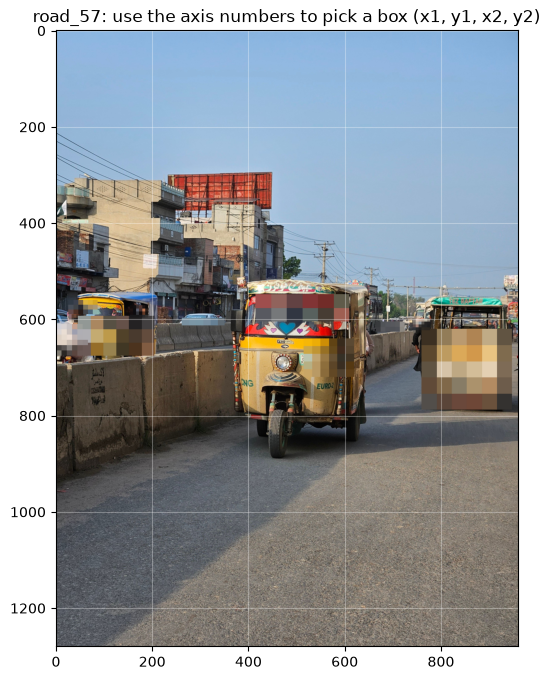

In [14]:
def show_with_coordinates(name):
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(results[name]["safe_image"])
    ax.grid(color="white", alpha=0.3)
    ax.set_title(f"{name}: use the axis numbers to pick a box (x1, y1, x2, y2)")
    plt.show()


def what_is_in_box(name, box):
    x1, y1, x2, y2 = box
    region = results[name]["class_map"][y1:y2, x1:x2]
    ids, counts = np.unique(region, return_counts=True)
    order = np.argsort(-counts)

    print(f"Inside box {box} of {name}:")
    for i in order:
        label = CLASS_NAMES[ids[i]] if ids[i] >= 0 else "(not sure / nothing)"
        print(f"  {label:22s} {100 * counts[i] / region.size:5.1f}%")

    safe = np.array(results[name]["safe_image"])[y1:y2, x1:x2]
    colored = color_by_class(region)
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(safe)
    axes[0].set_title("Crop")
    axes[1].imshow(blend(safe, colored, region >= 0, strength=0.7))
    axes[1].set_title("What the model sees")
    for ax in axes:
        ax.axis("off")
    plt.show()


show_with_coordinates("road_57")

Boxes were drawn around four Karachi-specific vehicles. The results are summarised in the conclusion (section 10).

Inside box (340, 500, 720, 880) of road_57:
  road                    30.7%
  (not sure / nothing)    26.9%
  wall                    24.9%
  building                 9.4%
  sky                      5.3%
  vegetation               1.6%
  car                      0.9%
  pole                     0.2%
  traffic sign             0.1%


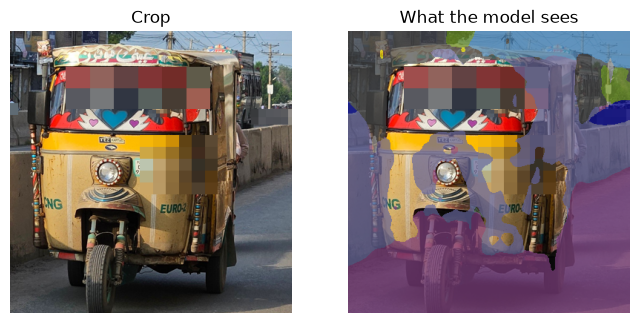

In [15]:
what_is_in_box("road_57", (340, 500, 720, 880))    # yellow auto-rickshaw, front view

Inside box (0, 60, 300, 400) of road_52:
  (not sure / nothing)    39.0%
  car                     21.9%
  vegetation              16.0%
  road                    11.5%
  motorcycle              10.1%
  building                 0.7%
  pole                     0.7%


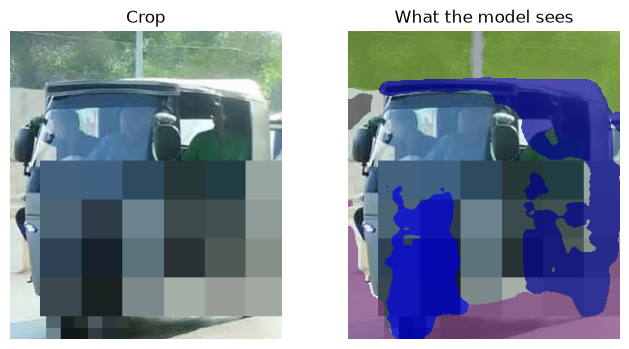

In [16]:
what_is_in_box("road_52", (0, 60, 300, 400))       # auto-rickshaw, side view

Inside box (100, 520, 800, 1080) of road_56:
  car                     65.4%
  road                    29.8%
  building                 3.9%
  wall                     0.5%
  person                   0.4%
  (not sure / nothing)     0.0%


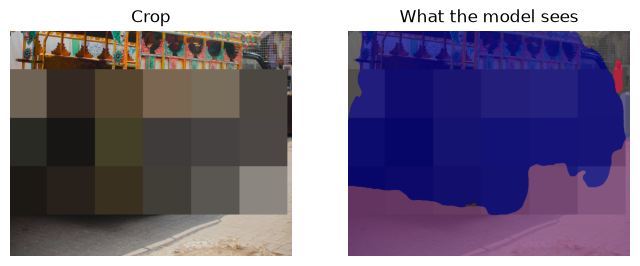

In [17]:
what_is_in_box("road_56", (100, 520, 800, 1080))   # decorated vehicle

Inside box (0, 700, 1280, 963) of road_45:
  road                    36.9%
  bicycle                 32.8%
  vegetation              30.0%
  person                   0.3%


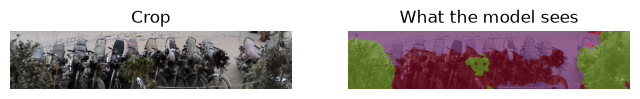

In [18]:
what_is_in_box("road_45", (0, 700, 1280, 963))     # row of parked motorcycles

## 9. Save the results

Only the **blurred** photo and the segmentation images are saved. The originals are never written anywhere by this notebook.

In [19]:
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

for name in photos:
    safe = results[name]["safe_image"]
    class_map = results[name]["class_map"]
    segment_map = results[name]["segment_map"]

    safe.save(os.path.join(OUTPUT_FOLDER, f"{name}_blurred.jpg"), quality=90)
    Image.fromarray(color_by_class(class_map)).save(os.path.join(OUTPUT_FOLDER, f"{name}_classes.png"))
    Image.fromarray(blend(safe, color_by_class(class_map), class_map >= 0)).save(
        os.path.join(OUTPUT_FOLDER, f"{name}_overlay.jpg"), quality=90)
    Image.fromarray(draw_instances(safe, segment_map, results[name]["segments"])).save(
        os.path.join(OUTPUT_FOLDER, f"{name}_instances.jpg"), quality=90)

print(f"Saved {len(os.listdir(OUTPUT_FOLDER))} files to '{OUTPUT_FOLDER}' (4 per photo)")

Saved 232 files to 'karachi_outputs' (4 per photo)


## 10. Observations and conclusion

### Summary
Mask2Former (trained on Cityscapes) was run on **58 photos of Karachi roads**. It found **905 segments**: 342 cars, 162 people, 24 bicycles, 18 riders, 11 trucks, 8 buses, 6 motorcycles and 1 train. On average, **road** covers a third of each photo (33%), followed by building (19%), sky (18%), terrain (8%), vegetation (6%) and car (5%).

The model does a good job on the parts of a Karachi road that look like a European road, and fails in clear, repeatable ways on the parts that don't.

### 1. What worked well
- **Stuff classes in normal street-level daylight photos:** road, sky, buildings and trees were segmented cleanly (for example `road_26`, `road_33`, `road_34`, `road_37`, `road_46`).
- **Cars:** in street-level shots, cars were found and separated as individual instances, even in long rows of traffic (`road_26`, `road_48`).
- **People:** pedestrians and people on motorbikes were usually found, even in crowded scenes (`road_44`, `road_45`, `road_54`).

### 2. Karachi vehicles the model has never seen
Cityscapes has no class for auto-rickshaws, Qingqis or decorated vehicles, and the `what_is_in_box` results show what happens:

| Object | What the model labelled it |
|---|---|
| Yellow auto-rickshaw, front view (`road_57`) | road 31%, not sure 27%, wall 25%: **not recognised as a vehicle at all** |
| Auto-rickshaw, side view (`road_52`) | not sure 39%, car 22%, motorcycle 10% |
| Decorated vehicle (`road_56`) | car 65% |
| Row of parked motorcycles (`road_45`) | **bicycle 33%, motorcycle 0%** |

- Rickshaws are either **missed completely** or split between *car*, *motorcycle* and *not sure*. The model forces them into the closest class it knows.
- **Motorcycles are mostly labelled as bicycles.** The model counted 24 bicycles but only 6 motorcycles, even though motorbikes are one of the most common vehicles on Karachi roads. Motorcycle is one of the rarest classes in Cityscapes, so the model has seen few examples of it.
- So the object counts in section 7 **can't be trusted as a traffic count**: there are far more motorbikes and rickshaws than the table shows.

### 3. Camera viewpoint
Cityscapes was filmed from a camera on a car, at street level. Many of these photos are not:
- **Photos from high buildings** (`road_05` to `road_23`, 19 photos of the same view): the model labelled rooftops, open plots and parts of the residential area as *road* and *terrain*, and missed most of the small vehicles on the road.
- **Dense traffic seen from above** (`road_01`, `road_04`): many vehicles in the jam were missed and labelled as road instead.
- **Photos through glass or from inside vehicles:** a car dashboard became *car* (`road_43`), and a photo through a rainy window became almost all *vegetation* (`road_32`).

### 4. Lighting and road conditions
- **Night:** Cityscapes contains only daytime images. In the night photo `road_30`, almost the whole image was labelled *sky*. (Other night photos with bright street lights, `road_49` and `road_50`, did better.)
- **Unclear road edges:** dirt medians, construction rubble and unpaved shoulders (`road_03`, `road_04`, `road_47`) were labelled inconsistently as road, wall, sidewalk or terrain. Labelling unpaved ground as *terrain* is reasonable, but without kerbs or lane markings the road/sidewalk border is often wrong.
- **Painted structures:** the green decorated pattern on the bridge in `road_44` and `road_45` was partly labelled *vegetation*.

### 5. Privacy: what the check by eye found
The automatic layers blurred **575 areas**. Checking every photo by eye still found **3 misses in 2 photos**, which I fixed with manual boxes (`EXTRA_BLUR_BOXES`):
- `road_57`: the **rickshaw's number plate was readable** and the driver area was not covered. The plate layer only blurs vehicles the model recognises, and it did not recognise the rickshaw.
- `road_48`: two pedestrians and a rickshaw driver were too small for both detectors.

**Lesson:** the domain gap is also a **privacy problem**. Anonymisation that depends on a model inherits that model's blind spots. Here, the objects the model doesn't know (rickshaws) are exactly the ones whose plates were left visible. Automatic blurring is a useful first step, but a human check is still necessary.

### 6. How the domain gap could be fixed
1. **Fine-tune on Karachi data:** label a few hundred Karachi street-level images and continue training the Cityscapes model on them. A small amount of local data usually helps a lot.
2. **Add new classes** such as *auto-rickshaw*, *Qingqi*, *animal cart* and *decorated truck/bus*. (The source repository includes hand-drawn labels for 11 of these photos with a *rickshaw* class, which is exactly the kind of data needed.)
3. **Collect data like the target use:** for a self-driving or traffic system, the photos should be taken from a vehicle at street level, including night, haze and rain.
4. **Open-vocabulary segmentation** (see Part 4): newer models can segment an object from a text prompt such as *"auto rickshaw"* without being trained on that class.

### 7. Limitations of this experiment
- The photos come from mixed sources (phone photos shared over WhatsApp, web images, Pexels). Many are low resolution or taken from far away, so this is not a controlled test set.
- There are no ground-truth masks for these photos, so I couldn't compute IoU or PQ. The analysis is based on looking at the results and on the `what_is_in_box` measurements.

### Conclusion
A state-of-the-art model trained on European streets gives a useful first segmentation of Karachi roads: it handles road, buildings, sky, cars and people well. But it **can't name what it was never taught**. Rickshaws become cars or are missed, motorcycles become bicycles, and unusual viewpoints and night scenes break it. Cityscapes covers 50 cities, but they are all similar European cities. To work reliably in Karachi, a model needs Karachi data with Karachi classes.

### References
1. Cordts, M. et al. (2016). *The Cityscapes Dataset for Semantic Urban Scene Understanding.* CVPR.
2. Cheng, B., Misra, I., Schwing, A., Kirillov, A., Girdhar, R. (2022). *Masked-attention Mask Transformer for Universal Image Segmentation (Mask2Former).* CVPR.
3. Kirillov, A., He, K., Girshick, R., Rother, C., Dollár, P. (2019). *Panoptic Segmentation.* CVPR.
4. Wu, W., Peng, H., Yu, S. (2023). *YuNet: A Tiny Millisecond-level Face Detector.* Machine Intelligence Research.